# Sprint 4 — ¿Por qué el modelo toma sus decisiones? (Machine Learning explicable)
**Pedido del docente (Semana 4):** un análisis que responda *"¿Por qué el modelo toma sus decisiones?"* con SHAP o
LIME. Por ejemplo, mostrar que el modelo le da más peso al ICFES que a la edad, con una explicación en español sencillo
de por qué eso tiene sentido para la Universidad.

| Sección | Contenido |
|---|---|
| 1 | Qué es SHAP y cómo se agrupan las variables en conceptos de negocio |
| 2 | Importancia global (modelo elegido vs. XGBoost) |
| 3 | Cómo cambia cada factor: descuento, distancia, Saber 11 y canal |
| 4 | Tres inscritos de la campaña 2027-1: SHAP vs. LIME |
| 5 | Chequeo independiente: importancia por permutación |
| 6 | Coherencia con las reglas de negocio y equidad por género |
| 7 | ¿El modelo encontró las causas reales? (comparación con el generador) |
| 8 | Explicaciones para el tablero (bloque 4) |

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repositorio: se sube de carpeta hasta encontrar config/reglas_negocio.yaml
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "reglas_negocio.yaml").exists())
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
EN_COLAB = False
SPRINTS = RAIZ / "sprints"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1B365D", "#E07B39", "#9AA5B1"

In [3]:
import caracteristicas as ca
import flujo
import modelado as mo

# Lee las tablas planas por la API de Supabase (solo lectura): dataset_matricula y la rúbrica de la entrevista
# (dataset_entrevista). Después construye las columnas del Sprint 2.
f = flujo.cargar_y_construir("supabase" if EN_COLAB else "auto")
d, ref, cfg = f["inscritos"], f["referencias"], ca.configuracion()
print("Origen de los datos:", f["origen"])
print(f"Inscritos: {len(d):,} · con entrevista: {int(d['entrevista_realizada'].sum()):,}")
print(d["particion"].value_counts().to_string())

Origen de los datos: Supabase (API de solo lectura)
Inscritos: 2,991 · con entrevista: 2,524
particion
ENTRENAMIENTO    1310
PRUEBA            761
VALIDACION        504
CAMPANA           416


In [4]:
# Hiperparámetros elegidos en el Sprint 3 (sprints/sprint_3_modelado/modelos/*.json)
PARAMETROS_FINALES = {'matricula': {'parametros': {'C': 0.01}, 'tipo': 'logistica'},
 'xgboost': {'parametros': {'learning_rate': 0.03,
                            'max_depth': 2,
                            'min_child_weight': 5,
                            'n_estimators': 200}}}

import joblib

MOD = SPRINTS / "sprint_3_modelado" / "modelos"
ruta_fondo = SPRINTS / "sprint_4_explicabilidad" / "resultados" / "fondo_shap.joblib"
fondos = joblib.load(ruta_fondo) if ruta_fondo.exists() else {}
art = {"referencias": ref,
       "modelo_matricula": joblib.load(MOD / "modelo_matricula.joblib")["modelo"],
       "modelo_matricula_xgboost": joblib.load(MOD / "modelo_matricula_xgboost.joblib")["modelo"],
       "logistica_sprint2": joblib.load(MOD / "logistica_sprint2_matricula.joblib")["modelo"]}
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
art["fondo_matricula"] = fondos.get("fondo_matricula", mo.preparar_X(hist, ref, mo.VARIABLES_MATRICULA).sample(300, random_state=1))
print("Modelos del Sprint 3 cargados:", ", ".join(k for k in art if k.startswith(("modelo", "logistica"))))

Modelos del Sprint 3 cargados: modelo_matricula, modelo_matricula_xgboost, logistica_sprint2


## 1. Qué es SHAP
SHAP reparte la predicción de cada inscrito entre sus variables, como un **reparto justo** entre jugadores de un equipo
(valores de Shapley, teoría de juegos). Para cada inscrito:

`log-odds predicho = valor base (inscrito promedio) + suma de las contribuciones de sus variables`

- Una contribución **positiva** sube la probabilidad de matrícula y una **negativa** la baja.
- Como las contribuciones **se suman**, las variables que miden la misma idea se agrupan en conceptos. Por ejemplo,
  la beca, el descuento y el valor neto forman "Beca y precio".
- En la regresión logística, SHAP es exacto: contribución = coeficiente × (valor − promedio).

In [5]:
import explicabilidad as ex
V = mo.VARIABLES_MATRICULA
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
X_hist = mo.preparar_X(hist, ref, V)
lm, xgb, fondo = art["modelo_matricula"], art["modelo_matricula_xgboost"], art["fondo_matricula"]
c_lm, base_lm = ex.contribuciones(lm, fondo, X_hist, V)
c_xg, _ = ex.contribuciones(xgb, fondo, X_hist, V)
g_lm, g_xg = ex.agrupar(c_lm, ex.GRUPOS_MATRICULA), ex.agrupar(c_xg, ex.GRUPOS_MATRICULA)
print(f"Valor base (probabilidad de un inscrito promedio): {1 / (1 + np.exp(-base_lm)):.1%}")
# Comprobación de la aditividad: base + suma de contribuciones = predicción del modelo
pred = lm.predict_proba(X_hist)[:, 1]
reconstruida = 1 / (1 + np.exp(-(base_lm + c_lm.sum(axis=1))))
print("Diferencia máxima entre la predicción y base + suma de SHAP:", float(np.abs(pred - reconstruida).max()).__round__(6))
display(pd.DataFrame([(g, ", ".join(v)) for g, v in ex.GRUPOS_MATRICULA.items()], columns=["concepto", "variables"]))

Valor base (probabilidad de un inscrito promedio): 45.7%
Diferencia máxima entre la predicción y base + suma de SHAP: 0.0


,concepto,variables
0,Beca y precio,"beca, pct_descuento_inicial, valor_neto_primer..."
1,Puntaje Saber 11,"punt_global, icfes_al_cuadrado"
2,Distancia al campus,log_distancia
3,Canal de captación,"canal, captado_en_evento"
4,Entrevista vocacional,"entrevista_realizada, indice_vocacional"
5,Apoyo FOES municipal,"apoyo_foes, elegible_foes"
6,Estrato y régimen de salud,"estrato, regimen_salud"
7,Programa,programa
8,Ingreso a mitad de año,semestre_2
9,Colegio de procedencia,"tipo_colegio, colegio_privado, colegio_en_conv..."


## 2. Importancia global
Importancia = el promedio del **valor absoluto** de la contribución, es decir, cuánto mueve un concepto la predicción
en cualquier sentido. Se compara con XGBoost: si dos modelos distintos señalan lo mismo, la conclusión es más sólida.

,regresion_logistica,xgboost,% del total
Beca y precio,0.385,0.376,29.777
Entrevista vocacional,0.174,0.163,13.480
Puntaje Saber 11,0.156,0.148,12.110
Canal de captación,0.137,0.173,10.612
Distancia al campus,0.134,0.154,10.355
Colegio de procedencia,0.071,0.037,5.465
Rendimiento en el colegio,0.048,0.028,3.739
Ingreso a mitad de año,0.040,0.000,3.083
Estrato y régimen de salud,0.039,0.009,2.979
Apoyo FOES municipal,0.031,0.008,2.406


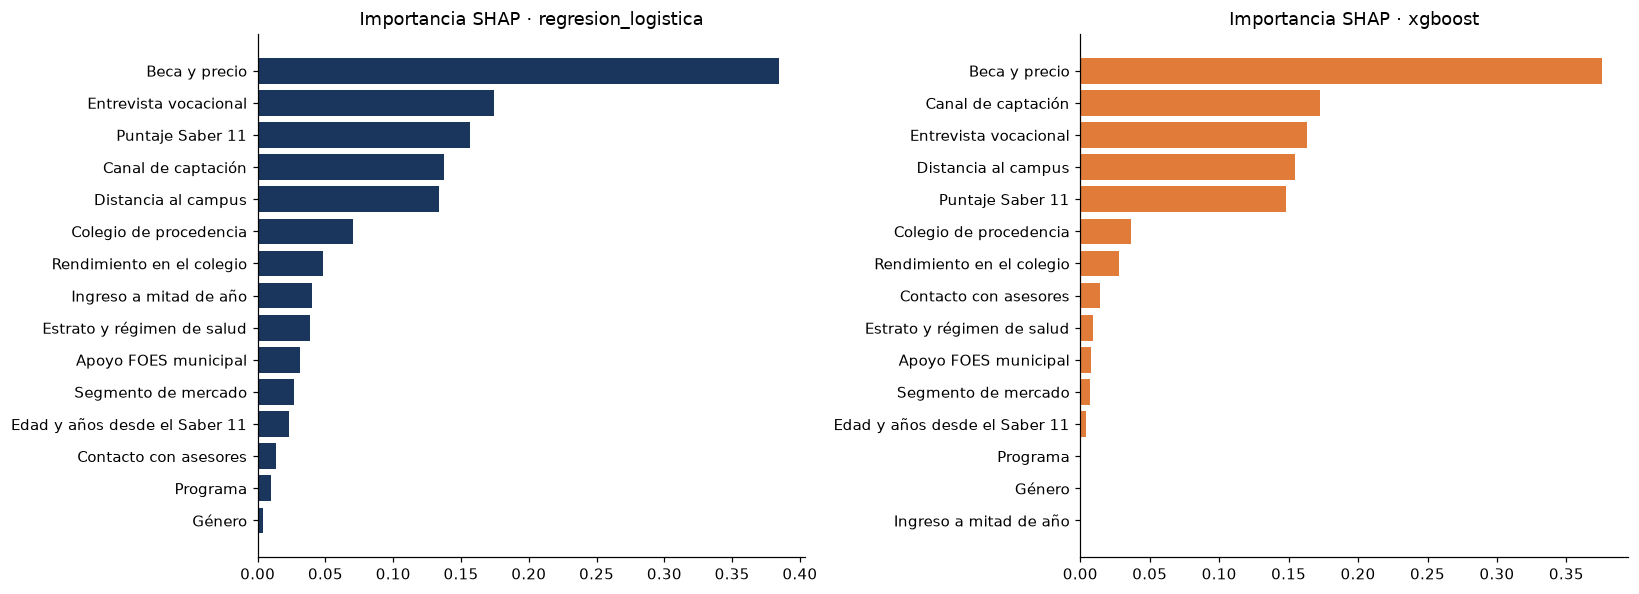

El modelo le da 6.7 veces más peso al puntaje Saber 11 que a la edad.


In [6]:
imp = pd.DataFrame({"regresion_logistica": ex.importancia(g_lm), "xgboost": ex.importancia(g_xg)}).sort_values("regresion_logistica", ascending=False)
imp["% del total"] = 100 * imp["regresion_logistica"] / imp["regresion_logistica"].sum()
display(imp.round(3))
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, col, color in [(ejes[0], "regresion_logistica", AZUL), (ejes[1], "xgboost", NARANJA)]:
    s = imp[col].sort_values(); ax.barh(s.index, s.values, color=color); ax.set_title(f"Importancia SHAP · {col}")
plt.tight_layout(); plt.show()
veces = imp.loc["Puntaje Saber 11", "regresion_logistica"] / imp.loc["Edad y años desde el Saber 11", "regresion_logistica"]
print(f"El modelo le da {veces:.1f} veces más peso al puntaje Saber 11 que a la edad.")

**En español sencillo.** Lo que más decide si un inscrito se matricula es **cuánto le cuesta** (beca y descuento). Le
siguen la **entrevista vocacional**, su **puntaje Saber 11**, la **distancia** desde su casa al campus y el **canal** por
el que llegó. La edad y el género pesan poco. Tiene sentido para la Universidad: el precio y la cercanía son barreras
reales, y quien tiene interés vocacional claro se compromete más.

## 3. Cómo cambia cada factor

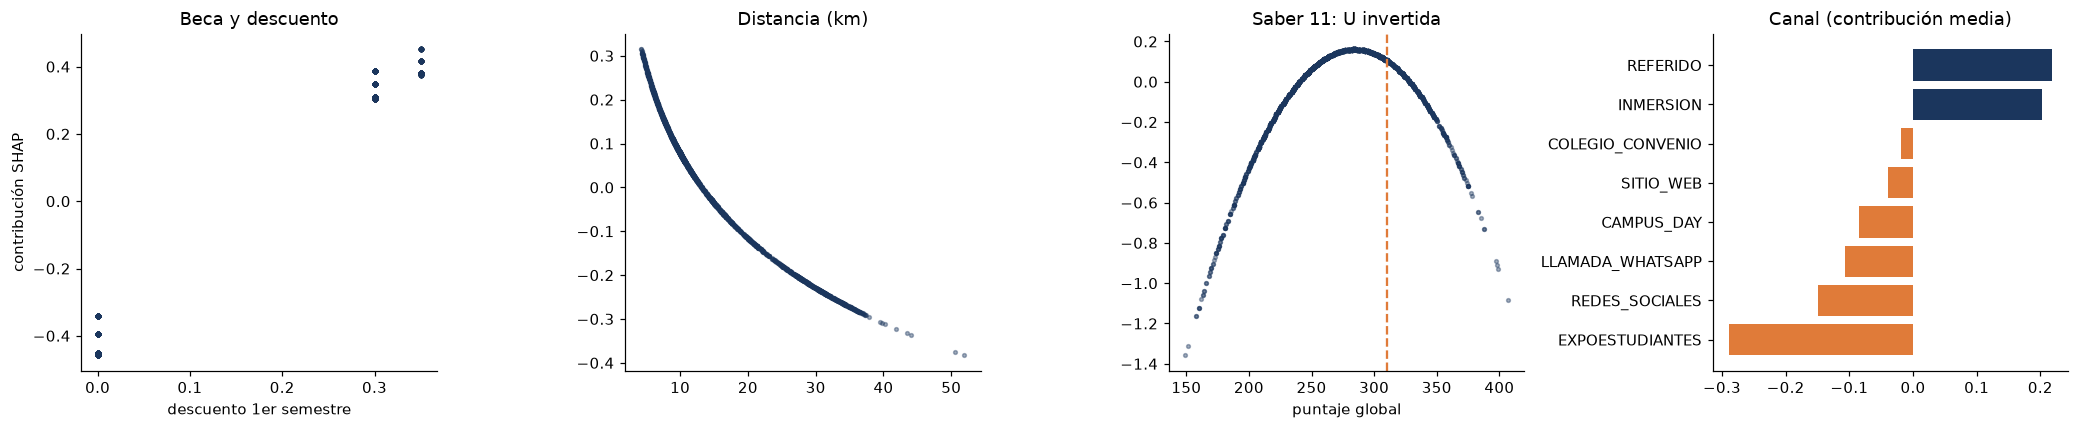

In [7]:
fig, ejes = plt.subplots(1, 4, figsize=(19, 4))
ejes[0].scatter(X_hist["pct_descuento_inicial"], c_lm[["pct_descuento_inicial", "valor_neto_primer_semestre", "beca"]].sum(axis=1), s=6, alpha=0.4, color=AZUL)
ejes[0].set(title="Beca y descuento", xlabel="descuento 1er semestre", ylabel="contribución SHAP")
ejes[1].scatter(np.exp(X_hist["log_distancia"]), c_lm["log_distancia"], s=6, alpha=0.4, color=AZUL); ejes[1].set(title="Distancia (km)")
ejes[2].scatter(X_hist["punt_global"], c_lm[["punt_global", "icfes_al_cuadrado"]].sum(axis=1), s=6, alpha=0.4, color=AZUL)
ejes[2].axvline(310, color=NARANJA, ls="--"); ejes[2].set(title="Saber 11: U invertida", xlabel="puntaje global")
canal = (c_lm["canal"] + c_lm["captado_en_evento"]).groupby(X_hist["canal"]).mean().sort_values()
ejes[3].barh(canal.index, canal.values, color=[NARANJA if x < 0 else AZUL for x in canal.values]); ejes[3].set(title="Canal (contribución media)")
plt.tight_layout(); plt.show()

## 4. Tres inscritos de la campaña 2027-1: SHAP vs. LIME
LIME explica **un** inscrito ajustando un modelo lineal sencillo con miles de "vecinos" simulados parecidos a él. Si
SHAP y LIME señalan los mismos factores, la explicación es más confiable.

In [8]:
camp = flujo.conjunto(d, "CAMPANA")
X_camp = mo.preparar_X(camp, ref, V)
prob_camp = pd.Series(lm.predict_proba(X_camp)[:, 1], index=camp.index)
casos = {n: (prob_camp - prob_camp.quantile(q)).abs().idxmin() for n, q in [("ALTA", 0.9), ("MEDIA", 0.5), ("BAJA", 0.1)]}
c_camp, _ = ex.contribuciones(lm, fondo, X_camp.loc[list(casos.values())], V)
g_camp = ex.agrupar(c_camp, ex.GRUPOS_MATRICULA)
for nombre, idx in casos.items():
    print(f"\n=== Propensión {nombre} · inscrito {int(camp.loc[idx, 'inscripcion_id'])} · probabilidad {prob_camp[idx]:.0%}")
    top = g_camp.loc[idx].reindex(g_camp.loc[idx].abs().sort_values(ascending=False).index)[:4]
    print("SHAP (conceptos):", "; ".join(f"{k} {v:+.2f}" for k, v in top.items()))
    lime = ex.explicar_lime(lm, X_hist.sample(800, random_state=2), X_camp.loc[[idx]], V, n_variables=5)
    print("LIME (reglas locales):", "; ".join(f"{k} {w:+.3f}" for k, w in lime))


=== Propensión ALTA · inscrito 1834 · probabilidad 66%
SHAP (conceptos): Beca y precio +0.31; Canal de captación +0.22; Entrevista vocacional +0.12; Puntaje Saber 11 +0.11


LIME (reglas locales): canal=REFERIDO +0.055; 0.00 < pct_descuento_inicial <= 0.30 +0.052; captado_en_evento <= 0.00 +0.051; punt_global > 302.00 +0.037; 3260600.00 < valor_neto_primer_semestre <= 3465000.00 +0.033

=== Propensión MEDIA · inscrito 1576 · probabilidad 47%
SHAP (conceptos): Beca y precio -0.45; Distancia al campus +0.28; Puntaje Saber 11 +0.13; Canal de captación -0.08


LIME (reglas locales): pct_descuento_inicial <= 0.00 -0.079; valor_neto_primer_semestre > 4658000.00 -0.064; log_distancia <= 2.19 +0.057; captado_en_evento > 0.00 -0.047; beca=NINGUNA -0.030

=== Propensión BAJA · inscrito 1154 · probabilidad 25%
SHAP (conceptos): Entrevista vocacional -0.52; Beca y precio -0.45; Colegio de procedencia +0.07; Rendimiento en el colegio -0.05


LIME (reglas locales): pct_descuento_inicial <= 0.00 -0.078; valor_neto_primer_semestre > 4658000.00 -0.066; indice_vocacional <= 15.00 -0.049; captado_en_evento <= 0.00 +0.049; promedio_acumulado_colegio <= 3.79 -0.035


## 5. Chequeo independiente: importancia por permutación
Se **desordena** un concepto en la prueba 2026-2, dejando lo demás igual, y se mide cuánto cae el AUC del modelo. No
usa SHAP: es otra forma de preguntar de qué depende el modelo.

In [9]:
ev, t = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION"), flujo.conjunto(d, "PRUEBA")
pm = PARAMETROS_FINALES["matricula"]     # el modelo elegido, reentrenado sin la prueba para medir en ella
lm_ev = mo.construir_pipeline(pm["tipo"], pm["parametros"], V, cfg["modelado"]["semilla"]).fit(
    mo.preparar_X(ev, ref, V), ev["matriculado"].astype(int))
perm = ex.importancia_permutacion(lm_ev, mo.preparar_X(t, ref, V), t["matriculado"].astype(int), ex.GRUPOS_MATRICULA)
display(perm.head(8).round(4))

,concepto,caida_auc,de_caida
0,Beca y precio,0.068,0.011
1,Entrevista vocacional,0.028,0.009
2,Puntaje Saber 11,0.027,0.004
3,Distancia al campus,0.010,0.006
4,Canal de captación,0.008,0.005
5,Apoyo FOES municipal,0.003,0.002
6,Colegio de procedencia,0.003,0.001
7,Segmento de mercado,0.002,0.001


## 6. Coherencia con las reglas de negocio y equidad
Cada afirmación se comprueba con los datos. La equidad se revisa de dos formas: el género debe pesar poco, y el
modelo no debe crear una diferencia entre hombres y mujeres que no exista en los datos reales.

In [10]:
coh = ex.chequeos_coherencia(X_hist, c_lm, g_lm, lm.predict_proba(X_hist)[:, 1], hist["matriculado"])
display(coh)
print(f"Cumple {int(coh['cumple'].sum())} de {len(coh)} reglas")

,regla,cumple,evidencia
0,Más descuento → más probabilidad de matrícula,True,correlación entre descuento y su contribución ...
1,Las becas pesan a favor frente a no tener beca,True,contribución media de la beca: MI_VOCACION +0....
2,Más distancia → menos probabilidad,True,correlación entre distancia y su contribución < 0
3,Saber 11 en U invertida: los puntajes muy alto...,True,"contribución media por banda: < 230 -0.34, 230..."
4,La entrevista vocacional pesa a favor,True,contribución media con entrevista > sin entrev...
5,El género NO domina las decisiones,True,puesto 15 de 15; importancia 0.004 vs. 0.385 d...
6,Paridad por género: el modelo no crea una brec...,True,brecha predicha F-M 0.010 vs. brecha real 0.011


Cumple 7 de 7 reglas


## 7. ¿El modelo encontró las causas reales?
Como los datos son sintéticos, se conocen los efectos **verdaderos** con los que se generó la matrícula
(`config/reglas_negocio.yaml → generador.matricula`). Es una prueba que con datos reales no se puede hacer: ¿la
explicación recupera la dirección de cada causa real?

In [11]:
gen = ex.comparar_con_generador(X_hist, c_lm, cfg)
display(gen)
print(f"Coinciden {int(gen['coincide'].sum())} de {len(gen)} efectos.")

,efecto,verdadero (generador),según SHAP,coincide
0,Descuento (beca),positivo (β = 3.0),positivo,True
1,Distancia al campus,negativo (β = -0.35),negativo,True
2,Saber 11 (término cuadrático),U invertida (β = -0.25),U invertida,True
3,Entrevista vocacional,positivo (β = 0.6),positivo,True
4,Apoyo FOES,positivo (β = 0.5),positivo,True
5,Programa SSIA,positivo (β = 0.1),positivo,True
6,Ingreso a mitad de año,negativo (β = -0.1),negativo,True
7,Canal (orden de los 8 canales),inmersión > referido > campus day/convenio > w...,correlación de Spearman con el orden real = 0.91,True
8,Estrato (orden de los 6 estratos),estrato 1 el más bajo; 4 el más alto,correlación de Spearman con el orden real = 0.32,False
9,Género (sin efecto real),ninguno (β = 0),importancia 0.004 log-odds,True


Coinciden 9 de 11 efectos.


**Lectura.** Los efectos grandes (beca, distancia, U invertida del Saber 11, entrevista, FOES, canal) se recuperan bien.
Fallan el orden del estrato (pocos casos en estratos 5 y 6) y el promedio del colegio: no tiene efecto en el generador,
pero el modelo le da algo de peso porque en los datos va de la mano con otras variables. **Lección:** una explicación
muestra lo que el modelo aprendió, no garantiza la causa.

## 8. Explicaciones para el tablero
Para cada inscrito se generan los **3 factores** que más mueven su probabilidad de matrícula, en español. Esta es la
tabla `explicacion_prediccion` (bloque 4 del tablero).

In [12]:
X_todos = mo.preparar_X(d, ref, V)
c_todos, _ = ex.contribuciones(lm, fondo, X_todos, V)
explicacion = ex.top_factores(ex.agrupar(c_todos, ex.GRUPOS_MATRICULA), X_todos, d["inscripcion_id"])
print(f"\nTabla del bloque 4: {len(explicacion):,} filas (3 por inscrito). Ejemplo:")
display(explicacion.head(6))


Tabla del bloque 4: 8,973 filas (3 por inscrito). Ejemplo:


,inscripcion_id,orden,factor,direccion,contribucion_log_odds,texto
0,1,1,Beca y precio,SUBE,0.380,"Beca y precio (beca Saber 11, descuento 35%): ..."
1,1,2,Distancia al campus,SUBE,0.218,Distancia al campus (vive a 6 km por vía): aum...
2,1,3,Colegio de procedencia,SUBE,0.195,Colegio de procedencia (colegio privado): aume...
3,2,1,Beca y precio,BAJA,-0.393,"Beca y precio (beca Ninguna, descuento 0%): re..."
4,2,2,Puntaje Saber 11,SUBE,0.145,Puntaje Saber 11 (puntaje global 298): aumenta...
5,2,3,Canal de captación,BAJA,-0.106,Canal de captación (llegó por llamada whatsapp...


## Conclusiones del Sprint 4
1. **Por qué decide así:** la beca y el precio explican más de una cuarta parte de las decisiones. Les siguen la
   entrevista, el Saber 11 (en U invertida), la distancia y el canal. La edad y el género pesan poco.
2. **Coherencia:** el modelo respeta las reglas de negocio y no crea brechas por género.
3. **Rigor:** SHAP recupera la mayoría de las causas reales del generador, y la importancia por permutación lo
   confirma.
4. **Para el tablero:** cada inscrito tiene sus 3 razones principales en español (`explicacion_prediccion`).